# 9. Electrons and two dimensions

**Goal.** Put electrons into DMRG (the Jordan–Wigner sign, written into an MPO by hand), then go to two dimensions: wrap the lattice into a cylinder, read off an order parameter with a pinning field, extrapolate to the infinite plane, and treat the 2D Hubbard model with the symmetries that make it affordable.

Real materials are made of electrons, and most open questions about them are two-dimensional: is the ground state ordered, a spin liquid, a superconductor? Electrons add one thing to everything so far, a sign: they are fermions. Two dimensions, done by DMRG on cylinders a few sites around, add three:

* the cylinder is a chain with long-range bonds, so $\chi$ grows exponentially with the width (notebook 12 measures it);
* on a finite system the order parameter of a broken symmetry is zero, so it has to be coaxed out;
* the answer is for a cylinder, and it has to be extrapolated to the plane.

Everything is checked against exact diagonalization on small clusters, and the final number against quantum Monte Carlo.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import dmrg_from_scratch as dmrg
from dmrg_from_scratch.exact import matvec_operator
from dmrg_from_scratch.fermions import AD, A, F, N, free_chain_correlation, hubbard_mpo

warnings.filterwarnings("ignore")  # TeNPy's notes about canonical form
RESULTS = Path("..") / "results"
Z = np.diag([1.0, -1.0])

## 1. Fermions on a chain: the Jordan–Wigner string

Take one spin orbital per qubit, $|0\rangle$ empty and $|1\rangle$ occupied, so $n = |1\rangle\langle1|$ and the annihilator on that orbital alone is $a = |0\rangle\langle1|$. Spin operators on different sites commute, but fermion operators anticommute, $c_ic_j = -c_jc_i$. The Jordan–Wigner map [P. Jordan and E. Wigner, [Z. Phys. 47, 631 (1928)](https://doi.org/10.1007/BF01331938)] supplies the sign with a string that counts the electrons to the left:

$$c_j = F_0F_1\cdots F_{j-1}\,a_j, \qquad F = (-1)^n = Z.$$

The exact TFIM energies used since notebook 2 (`exact.py`) come from the same map, used the other way: there it turns spins into free fermions. For a hop $p < q$ the strings left of $p$ cancel ($F^2 = 1$, and $a^\dagger F = a^\dagger$ on one orbital), leaving

$$c^\dagger_pc_q = a^\dagger_p\,F_{p+1}\cdots F_{q-1}\,a_q:$$

an $F$ on every orbital the electron jumps over.

**The Hubbard chain as an MPO.** $H = -t\sum_{i\sigma}(c^\dagger_{i\sigma}c_{i+1,\sigma} + \text{h.c.}) + U\sum_i n_{i\uparrow}n_{i\downarrow} - \mu\sum_{i\sigma}n_{i\sigma}$. Site $i$ is stored as two interleaved orbitals, $2i$ (up) and $2i+1$ (down). Every tensor stays $2\times2$, as for the spin chains, and the sign stays visible: a hop from $2i$ to $2i+2$ passes orbital $2i+1$, so the MPO channel that carries it applies $F$ there where a spin chain would apply $I$. The finite-state machine of notebook 2 now has 7 states:

| state | meaning | the next orbital applies |
|---|---|---|
| 0 | start | $I$ (stay in 0), $a^\dagger$ (to 1), $a$ (to 2), $n$ (to 5, up orbitals only), $-\mu n$ (to 6) |
| 1, 2 | $a^\dagger$ or $a$ placed | $F$ (to 3 or 4): the string |
| 3, 4 | one orbital passed | $-t\,a$ or $-t\,a^\dagger$ (to 6): the hop is complete |
| 5 | $n_\uparrow$ placed | $U n_\downarrow$ (to 6), on the down orbital of the same site |
| 6 | done | $I$ |

`hubbard_mpo` in `fermions.py` writes these as two tensors, one for up and one for down orbitals. Check them against the qubit Hamiltonian of `hubbard_cylinder` (width 1 is a chain), which is built term by term from Pauli strings:

In [2]:
L, U = 3, 4.0
mpo = hubbard_mpo(L, U, mu=U / 2)
print("MPO tensor shapes:", [W.shape for W in mpo[:3]], "...")
Hq = dmrg.hubbard_cylinder(1, L, U)  # U (n_up - 1/2)(n_dn - 1/2): U/4 per site above U n n - (U/2) n
dense = matvec_operator(Hq) @ np.eye(2**Hq.n)
print("largest difference:", np.abs(dmrg.mpo_to_dense(mpo) + U * L / 4 * np.eye(2**Hq.n) - dense).max())

MPO tensor shapes: [(1, 7, 2, 2), (7, 7, 2, 2), (7, 7, 2, 2)] ...
largest difference: 0.0


**Free fermions.** At $U = 0$ the chain is solvable: the standing waves $\phi_k(j) = \sin(\pi kj/(L+1))$, $j = 1..L$, satisfy $-t\,(\phi_k(j-1) + \phi_k(j+1)) = -2t\cos(\pi k/(L+1))\,\phi_k(j)$ with $\phi_k(0) = \phi_k(L+1) = 0$. The single-particle energies are $\varepsilon_k = -2t\cos(\pi k/(L+1))$, and the ground state fills every negative one, once per spin (`free_chain_energy`).

**The right filling.** `finite.dmrg` knows nothing about the electron number: it finds the lowest state of $H$ among all fillings. At $U = 0$, $\mu = 0$ that is half filling. At $U > 0$ the chemical potential $\mu = U/2$, the particle-hole symmetric point, puts the lowest state at half filling again; its energy is lower by $\mu N$, which we add back. Any other filling needs a tuned $\mu$ or a penalty $\lambda(N - N_0)^2$, and nothing stops the state from mixing fillings on the way. That is the motivation for conserving $N$ in the MPS itself (section 5).

In [3]:
L = 6
t0 = time.time()
r0 = dmrg.dmrg(hubbard_mpo(L, 0.0), chi_max=64, n_sweeps=4)
print(f"U = 0: DMRG {r0['energy']:.12f}   free fermions {dmrg.free_chain_energy(L):.12f}   ({time.time() - t0:.1f} s)")

U = 4.0
E_ph, _ = dmrg.ground_state(dmrg.hubbard_cylinder(1, L, U))  # exact diagonalization, 12 qubits
r4 = dmrg.dmrg(hubbard_mpo(L, U, mu=U / 2), chi_max=64, n_sweeps=4)
n_total = sum(dmrg.product_expectation(r4["mps"], {p: N}) for p in range(2 * L))
print(f"U = 4: DMRG {r4['energy'] + U / 2 * L:.12f}   exact {E_ph + U * L / 4:.12f}   electrons {n_total:.6f}")

U = 0: DMRG -6.987918414870   free fermions -6.987918414870   (0.9 s)


U = 4: DMRG -3.092565319505   exact -3.092565319505   electrons 6.000000


**The silent sign bug.** Measure the hopping correlation $\langle c^\dagger_{0\uparrow}c_{j\uparrow}\rangle$ in the free ground state, once with the string and once without, against the exact $\sum_{k\ \text{occupied}}\phi_k(1)\phi_k(j+1)$ (normalized standing waves; `free_chain_correlation`). `product_expectation` takes any product of one-site operators:

In [4]:
print(" j   with string   without string   exact")
for j in range(1, 6):
    q = 2 * j  # spin-up orbital of site j
    string = {k: F for k in range(1, q)}
    right = dmrg.product_expectation(r0["mps"], {0: AD, q: A, **string})
    wrong = dmrg.product_expectation(r0["mps"], {0: AD, q: A})
    print(f"{j:2d}   {right:+.6f}     {wrong:+.6f}        {free_chain_correlation(L, 0, j):+.6f}")

 j   with string   without string   exact


 1   +0.435560     -0.000000        +0.435560


 2   +0.000000     -0.159787        +0.000000


 3   -0.193842     +0.000000        -0.193842


 4   -0.000000     +0.099625        -0.000000


 5   +0.150708     +0.000000        +0.150708


The energy is right either way (the MPO has its $F$), but without the string every correlator over a distance is wrong: here it vanishes where the true one is large and is large where the true one vanishes. Nothing crashes. Packages such as TeNPy insert the strings for you, which is reason enough to use one for fermions.

**Why metals are harder.** A gapped state obeys the area law, $S \sim L^{d-1}$ for a region of linear size $L$ in $d$ dimensions. Free fermions with a Fermi surface break it by a logarithm, $S \sim L^{d-1}\log L$ [M. M. Wolf, [arXiv:quant-ph/0503219](https://arxiv.org/abs/quant-ph/0503219); [PRL 96, 010404 (2006)](https://doi.org/10.1103/PhysRevLett.96.010404); D. Gioev and I. Klich, [arXiv:quant-ph/0504151](https://arxiv.org/abs/quant-ph/0504151); [PRL 96, 100503 (2006)](https://doi.org/10.1103/PhysRevLett.96.100503)]. In one dimension this is the critical $\log L$ of notebook 3. On a cylinder the extra factor means the entanglement, and so $\log_2\chi$, grows faster with the width for a metal than for an insulator. Doped Hubbard cylinders, which are metallic, are the hard case of section 5 and of notebook 10.

## 2. A cylinder is a chain with long-range bonds

Number the sites column by column, $s = xW + y$ (open along $x$, periodic around $y$), and DMRG sees a chain. Bonds around the cylinder have range 1 (or $W-1$ across the seam); bonds along it have range $W$. The MPO must carry every bond that crosses a cut, so its bond dimension grows with $W$:

In [5]:
for W in (2, 4, 6):
    H = dmrg.j1j2_cylinder(W, Lx=4, J2=0.0)  # square-lattice Heisenberg model, S = sigma/2
    ranges = sorted({j - i for i, j in dmrg.cylinder_bonds(4, W)})
    w = max(Wt.shape[1] for Wt in dmrg.build_mpo(H))
    print(f"W = {W}: bond ranges in the chain {ranges}, MPO bond dimension {w}")

W = 2: bond ranges in the chain [1, 2], MPO bond dimension 8
W = 4: bond ranges in the chain [1, 3, 4], MPO bond dimension 14
W = 6: bond ranges in the chain [1, 5, 6], MPO bond dimension 20


A cut through the middle of the cylinder crosses $W$ bonds, so an area-law state has $S \approx aW$ and needs $\chi \sim 2^{aW}$. Notebook 12 measures this; here we take it as the price of admission and ask what DMRG can learn on the widths it can reach.

## 3. Néel order from one expectation value: pinning fields

The square-lattice Heisenberg antiferromagnet $H = \sum_{\langle ij\rangle}\mathbf S_i\cdot\mathbf S_j$ has Néel order in the plane: each sublattice carries a magnetization $M_0$. On any finite cluster, though, the ground state is a spin singlet and $\langle S^z_i\rangle = 0$ on every site. The order only shows in correlations, and those decay to $M_0^2$ slowly with distance.

White and Chernyshev's trick [[arXiv:0705.2746](https://arxiv.org/abs/0705.2746)] is to break the symmetry by hand at the edges: a staggered field $\tfrac12(-1)^{x+y} S^z$ on the first and last column (what a frozen Néel neighbour beyond each end would exert). The bulk then picks that Néel state, and $M_C = |\langle S^z\rangle|$ in the middle column measures the order. `neel_pinning` adds the field; `site_expectations` measures one-site operators on an MPS.

Live, on a $4\times4$ cylinder (16 spins), against exact diagonalization:

In [6]:
H = dmrg.neel_pinning(dmrg.j1j2_cylinder(4, Lx=4, J2=0.0))
E0, psi0 = dmrg.ground_state(H)
bits = (np.arange(2**H.n)[:, None] >> (H.n - 1 - np.arange(H.n))) & 1
M_exact = np.abs(0.5 * (psi0**2) @ (1 - 2 * bits)).reshape(4, 4).mean(axis=1)

r = dmrg.dmrg(dmrg.build_mpo(H), chi_max=32, n_sweeps=3)
M_dmrg = np.abs(0.5 * dmrg.site_expectations(r["mps"], Z)).reshape(4, 4).mean(axis=1)
print("E - E0 =", f"{r['energy'] - E0:.1e}")
print("|<S^z>| by column, exact:", M_exact.round(4))
print("|<S^z>| by column, DMRG :", M_dmrg.round(4))

H_free = dmrg.j1j2_cylinder(4, Lx=4, J2=0.0)
r_free = dmrg.dmrg(dmrg.build_mpo(H_free), chi_max=32, n_sweeps=3)
print("without pinning, largest |<S^z>|:", f"{np.abs(dmrg.site_expectations(r_free['mps'], Z)).max() / 2:.1e}")

E - E0 = 4.7e-04
|<S^z>| by column, exact: [0.3918 0.3463 0.3463 0.3918]
|<S^z>| by column, DMRG : [0.392  0.3465 0.3465 0.392 ]


without pinning, largest |<S^z>|: 1.6e-05


The magnetization is largest next to the pinned edges and drops towards the middle. Without the field it vanishes, as it must for a singlet.

The same calculation in TeNPy, which conserves total $S^z$ and so splits every tensor into blocks (notebook 5), reaches $8\times4$ in seconds:

In [7]:
from tenpy.algorithms import dmrg as tdmrg
from tenpy.models.spins import SpinModel
from tenpy.networks.mps import MPS


def pinned_heisenberg(W, Lx):
    hz = np.zeros((Lx, W))
    for x in (0, Lx - 1):
        hz[x] = [-0.5 * (-1) ** (x + y) for y in range(W)]  # SpinModel adds -hz S^z
    return SpinModel({"lattice": "Square", "Lx": Lx, "Ly": W, "bc_x": "open", "bc_y": "periodic",
                      "bc_MPS": "finite", "S": 0.5, "Jx": 1.0, "Jy": 1.0, "Jz": 1.0, "hz": hz, "conserve": "Sz"})


W, Lx = 4, 8
model = pinned_heisenberg(W, Lx)
neel = ["down" if (k // W + k % W) % 2 == 0 else "up" for k in range(W * Lx)]
psi = MPS.from_product_state(model.lat.mps_sites(), neel)
t0 = time.time()
for chi in (32, 64, 128):
    eng = tdmrg.TwoSiteDMRGEngine(psi, model, {"trunc_params": {"chi_max": chi}, "mixer": chi == 32,
                                                "max_sweeps": 2, "min_sweeps": 2, "max_trunc_err": 1.0})
    E, _ = eng.run()
    M_x = np.abs(psi.expectation_value("Sz")).reshape(Lx, W).mean(axis=1)
    print(f"chi = {chi:3d}   E = {E:.6f}   truncation error {eng.sweep_stats['max_trunc_err'][-1]:.1e}"
          f"   M_C = {M_x[Lx // 2 - 1:Lx // 2 + 1].mean():.4f}   {time.time() - t0:.1f} s")

chi =  32   E = -22.257791   truncation error 5.0e-05   M_C = 0.2828   1.1 s


chi =  64   E = -22.262419   truncation error 1.8e-06   M_C = 0.2799   2.5 s


chi = 128   E = -22.262681   truncation error 7.2e-08   M_C = 0.2797   4.2 s


## 4. Two extrapolations: in the truncation error, then in the width

Every DMRG number has two errors. The first comes from the finite bond dimension. Both the energy and a local quantity such as $M_C$ depend smoothly on the truncation error $\varepsilon$ (the discarded weight), close to linearly, so one runs a ladder of $\chi$ and extrapolates to $\varepsilon \to 0$ [White and Chernyshev]. The distance from the last point to the extrapolation is a fair error bar; following them we quote 0.2 times that distance.

The full runs: widths $W = 4, 6, 8$ at aspect ratios $L_x/W = 1, 1.5, 2$, up to $\chi = 768$ (from `python scripts/make_results.py neel_pinned`, TeNPy, about half an hour on 4 cores).

 4 x 4  alpha = 1.0   M_C = 0.3463 +- 0.0000   E/N = -0.71204 +- 0.00000
 6 x 4  alpha = 1.5   M_C = 0.3100 +- 0.0000   E/N = -0.70088 +- 0.00000
 8 x 4  alpha = 2.0   M_C = 0.2797 +- 0.0000   E/N = -0.69571 +- 0.00000
 6 x 6  alpha = 1.0   M_C = 0.3440 +- 0.0000   E/N = -0.69465 +- 0.00000
 9 x 6  alpha = 1.5   M_C = 0.3172 +- 0.0000   E/N = -0.68692 +- 0.00000
12 x 6  alpha = 2.0   M_C = 0.2985 +- 0.0000   E/N = -0.68319 +- 0.00000
 8 x 8  alpha = 1.0   M_C = 0.3377 +- 0.0001   E/N = -0.68780 +- 0.00000
12 x 8  alpha = 1.5   M_C = 0.3173 +- 0.0002   E/N = -0.68194 +- 0.00001
16 x 8  alpha = 2.0   M_C = 0.3026 +- 0.0004   E/N = -0.67908 +- 0.00001


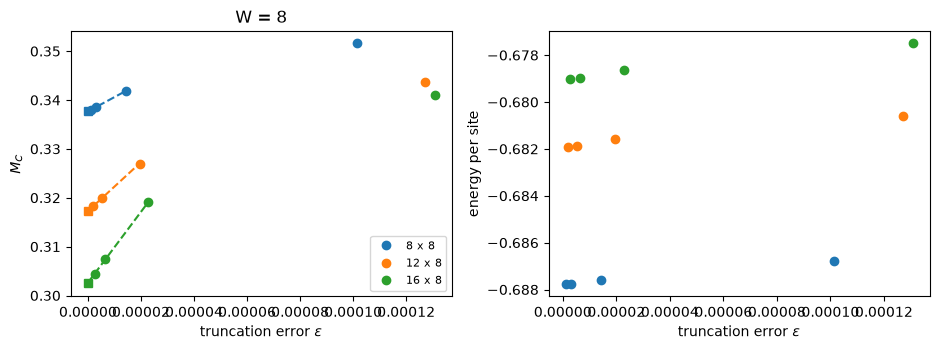

In [8]:
data = json.loads((RESULTS / "neel_pinned.json").read_text())


def middle(row, Lx):
    return float(np.mean(row["M_x"][Lx // 2 - 1 : Lx // 2 + 1]) if Lx % 2 == 0 else row["M_x"][Lx // 2])


def extrapolate(eps, y, n_fit=3):
    # linear fit in the truncation error on the n_fit largest chi; error = 0.2 x the extrapolation distance
    b, a = np.polyfit(eps[-n_fit:], y[-n_fit:], 1)
    return a, 0.2 * abs(y[-1] - a)


fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
table = []
for c in data["clusters"]:
    W, Lx = c["W"], c["Lx"]
    eps = np.array([r["trunc_err"] for r in c["runs"]])
    M = np.array([middle(r, Lx) for r in c["runs"]])
    E = np.array([r["energy"] for r in c["runs"]])
    M0, dM = extrapolate(eps, M)
    E0, dE = extrapolate(eps, E)
    table.append({"W": W, "Lx": Lx, "alpha": Lx / W, "M": M0, "dM": dM, "E": E0, "dE": dE})
    if W == 8:
        line, = ax[0].plot(eps, M, "o", label=f"{Lx} x {W}")
        x = np.linspace(0, eps[-3:].max(), 20)
        ax[0].plot(x, np.polyval(np.polyfit(eps[-3:], M[-3:], 1), x), "--", color=line.get_color())
        ax[0].errorbar([0], [M0], [dM], fmt="s", color=line.get_color())
        ax[1].plot(eps, E / (W * Lx), "o", color=line.get_color(), label=f"{Lx} x {W}")
ax[0].set(xlabel=r"truncation error $\varepsilon$", ylabel="$M_C$", title="W = 8")
ax[1].set(xlabel=r"truncation error $\varepsilon$", ylabel="energy per site")
ax[0].legend(fontsize=8)
fig.tight_layout()
for t in table:
    print(f"{t['Lx']:2d} x {t['W']}  alpha = {t['alpha']:.1f}   M_C = {t['M']:.4f} +- {t['dM']:.4f}"
          f"   E/N = {t['E'] / (t['W'] * t['Lx']):.5f} +- {t['dE'] / (t['W'] * t['Lx']):.5f}")

The second error comes from the finite cylinder. For a fixed aspect ratio $\alpha = L_x/W$, $M_C$ approaches the bulk value $M_0$ as $W$ grows, but from opposite sides: a long cylinder ($\alpha$ large) looks one-dimensional and fluctuates more, so $M_C < M_0$; a short one is dominated by the pinned edges, so $M_C > M_0$ [White and Chernyshev]. The reference is the quantum Monte Carlo value $M_0 = 0.30743(1)$ of Sandvik and Evertz [[arXiv:0807.0682](https://arxiv.org/abs/0807.0682); [PRB 82, 024407 (2010)](https://doi.org/10.1103/PhysRevB.82.024407)], from lattices up to $256\times256$; at $J_2 = 0$ there is no sign problem, so QMC is essentially exact here.

W = 8 brackets the answer: 0.3026 (alpha = 2) < 0.3074 < 0.3173 (alpha = 1.5)


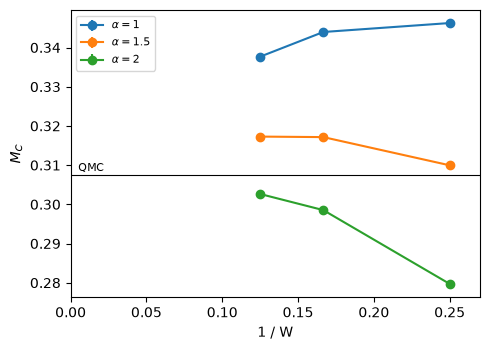

In [9]:
alpha = np.array([t["alpha"] for t in table])
Ws = np.array([t["W"] for t in table])
Ms = np.array([t["M"] for t in table])
dMs = np.array([t["dM"] for t in table])

fig, ax = plt.subplots(figsize=(5, 3.6))
for al in sorted(set(alpha)):
    sel = alpha == al
    ax.errorbar(1 / Ws[sel], Ms[sel], dMs[sel], fmt="o-", label=rf"$\alpha = {al:g}$")
ax.axhline(0.30743, color="k", lw=0.8)
ax.text(0.005, 0.3085, "QMC", fontsize=8)
ax.set(xlabel="1 / W", ylabel="$M_C$", xlim=(0, 0.27))
ax.legend(fontsize=8)
fig.tight_layout()
w8 = {t["alpha"]: t["M"] for t in table if t["W"] == 8}
print(f"W = 8 brackets the answer: {w8[2.0]:.4f} (alpha = 2) < 0.3074 < {w8[1.5]:.4f} (alpha = 1.5)")

The bracket is the robust statement. To get a number one must assume a form for the approach. White and Chernyshev use $M_C(\alpha, W) = M_0 + a(\alpha - \alpha_c)/W$: at a "magic" aspect ratio $\alpha_c$ the $1/W$ term vanishes. Here it is fitted on all clusters, on the two widest only, and with $1/W^2$ terms added:

In [10]:
def fit(sel, extra=False):
    cols = [np.ones(sel.sum()), alpha[sel] / Ws[sel], -1 / Ws[sel]]  # linear in (M0, a, a alpha_c)
    if extra:
        cols += [alpha[sel] / Ws[sel] ** 2, 1 / Ws[sel] ** 2]
    coef, *_ = np.linalg.lstsq(np.column_stack(cols), Ms[sel], rcond=None)
    return coef[0]


for label, sel, extra in [("all widths, 1/W", Ws > 0, False), ("W = 6, 8 only, 1/W", Ws >= 6, False),
                          ("all widths, 1/W and 1/W^2", Ws > 0, True)]:
    print(f"{label:28s} M0 = {fit(sel, extra):.4f}")
print(f"{'QMC':28s} M0 = 0.3074")

all widths, 1/W              M0 = 0.3284
W = 6, 8 only, 1/W           M0 = 0.3171
all widths, 1/W and 1/W^2    M0 = 0.2986
QMC                          M0 = 0.3074


Three reasonable fits spread over about 10%, from a few percent below QMC to several percent above it. At widths up to 8 the corrections beyond $1/W$ are not small, and the extrapolation in width, not the bond dimension, is the dominant and least controlled error. White and Chernyshev needed widths up to 10 and clusters rotated by 45° to reach $M_0 = 0.3067$ within about $10^{-3}$ of QMC. This is the shape of every 2D DMRG result: two extrapolations, each with its own error, and a number that is only as good as the widest cylinder.

## 5. Electrons in two dimensions: the Hubbard model

The Hubbard model of section 1, the minimal model of electrons in a solid, now on a cylinder:

$$H = -t\sum_{\langle ij\rangle,\sigma}\left(c^\dagger_{i\sigma}c_{j\sigma} + \text{h.c.}\right) + U\sum_i n_{i\uparrow}n_{i\downarrow}.$$

In Pauli form ($a^\dagger_pF\cdots Fa_q + \text{h.c.} = \tfrac12(X_pZ\cdots ZX_q + Y_pZ\cdots ZY_q)$), a hop along the cylinder jumps over about $2W$ orbitals, so its string carries about $2W$ $Z$'s. `hubbard_cylinder` builds this for exact diagonalization.

In [11]:
Hq = dmrg.hubbard_cylinder(2, 4, U=4.0)  # 4 x 2 ladder, 16 qubits
print(Hq.name, "|", Hq.n, "qubits |", len(Hq.terms), "Pauli terms")
print("a hop along the ladder:", max(Hq.terms, key=lambda t: len(t[1]))[1])
t0 = time.time()
E_ed, _ = dmrg.ground_state(Hq)
E_ed += 4.0 * 8 / 4  # hubbard_cylinder uses U (n_up - 1/2)(n_dn - 1/2); U n_up n_dn is U/4 higher per site
print(f"exact diagonalization: E0 = {E_ed:.10f}  ({time.time() - t0:.1f} s)")

Hubbard, U = 4, t = 1 | 16 qubits | 48 Pauli terms
a hop along the ladder: ((0, 'X'), (1, 'Z'), (2, 'Z'), (3, 'Z'), (4, 'X'))


exact diagonalization: E0 = -5.0125031527  (0.3 s)


TeNPy inserts the Jordan–Wigner strings itself, with one $d = 4$ site (empty, up, down, both) per lattice site. What makes electrons affordable is symmetry: the Hamiltonian conserves the electron number $N$ and $S^z$, so every MPS bond splits into sectors labelled $(N, 2S^z)$, and every tensor into blocks. Compare the same run with and without them. Without them we add a chemical potential $\mu = U/2$, which puts the lowest state at half filling; its energy is then lower by $\mu N$.

In [12]:
from tenpy.models.hubbard import FermiHubbardModel


def hubbard_run(W, Lx, U, chi, conserve=True):
    p = {"lattice": "Square", "Lx": Lx, "Ly": W, "bc_x": "open", "bc_y": "periodic" if W > 2 else "open",
         "bc_MPS": "finite", "t": 1.0, "U": U, "mu": 0.0 if conserve else U / 2}
    if not conserve:
        p.update(cons_N=None, cons_Sz=None)
    model = FermiHubbardModel(p)
    init = ["up" if (k // W + k % W) % 2 == 0 else "down" for k in range(W * Lx)]  # half filling, S^z = 0
    psi = MPS.from_product_state(model.lat.mps_sites(), init)
    t0 = time.time()
    info = tdmrg.run(psi, model, {"trunc_params": {"chi_max": chi, "svd_min": 1e-10}, "mixer": True,
                                  "max_sweeps": 20, "max_E_err": 1e-10, "max_trunc_err": 1.0})
    E = info["E"] + (0.0 if conserve else U / 2 * W * Lx)
    return E, time.time() - t0, psi


for conserve in (True, False):
    E, sec, psi = hubbard_run(2, 4, 4.0, 256, conserve)
    print(f"conserve N and Sz = {conserve!s:5}:  E - E_ED = {E - E_ed:+.1e}   {sec:.1f} s")

conserve N and Sz = True :  E - E_ED = -6.2e-15   0.9 s


conserve N and Sz = False:  E - E_ED = -7.1e-15   3.2 s


The same energy, several times faster. The reason is visible on the middle bond: the 256 states fall into a few dozen charge sectors, and the eigensolver and SVDs work on each block separately, so the cost is a sum of small cubes instead of one large one.

In [13]:
E, sec, psi = hubbard_run(2, 4, 4.0, 256)
leg = psi.get_B(psi.L // 2, "B").get_leg("vL")
sizes = np.diff(leg.slices)
print(f"middle bond: chi = {leg.ind_len}, {leg.block_number} sectors (N, 2Sz), largest block {sizes.max()}")
print(f"chi^3 = {leg.ind_len**3:.1e}  versus  sum of block^3 = {np.sum(sizes**3):.1e}")

middle bond: chi = 256, 25 sectors (N, 2Sz), largest block 36
chi^3 = 1.7e+07  versus  sum of block^3 = 1.2e+05


Electron number and $S^z$ give abelian (U(1)) symmetries. Codes that also use the full SU(2) spin symmetry split the tensors further. Notebook 10 puts a width-4 Hubbard calculation next to other methods.

## Summary

* Fermions are spins plus a string, $c_j = F_0\cdots F_{j-1}a_j$. In an MPO the string is the operator a channel applies to the orbitals a hop passes; forget it in a correlator and the answer is silently wrong.
* Plain DMRG does not fix the electron number. A chemical potential at the particle-hole symmetric point does at half filling; conserved quantum numbers do in general.
* A cylinder is a chain with bonds of range $W$; the MPO and, much more, the MPS grow with the width.
* A staggered field on the edges turns the order parameter into a local expectation value $M_C$.
* Each number needs two extrapolations: in the truncation error (linear, error bar 0.2 times the jump) and in the width. Widths up to 8 bracket $M_0$ between two aspect ratios, but the fitted value depends on the assumed form at the 10% level: the width is the error that matters.
* For electrons, conserving $N$ and $S^z$ splits every tensor into blocks; this is what makes the Hubbard model affordable.

## Exercises

1. Remove the pinning field from the $8\times4$ TeNPy run and measure $\langle S^z_0 S^z_r\rangle$ along the middle row instead. How far apart must the spins be before the correlation is within 10% of $M_0^2$?
2. Change the pinning field from $1/2$ to $1$ and to $1/4$ on the $8\times4$ cylinder. Which aspect ratio now makes $M_C$ insensitive to the width?
3. Turn on the frustrating diagonal coupling in the live $4\times4$ run, `j1j2_cylinder(4, Lx=4, J2=0.5)`. What happens to $M_C$, and how much larger must $\chi$ be for the same energy error?
4. Build the MPO of the spinless chain $-t\sum_i(c^\dagger_ic_{i+1} + \text{h.c.}) + V\sum_in_in_{i+1}$ with one orbital per site. Does it need $F$ at all? Add a next-nearest-neighbour hop: where does $F$ appear now?
5. In `hubbard_cylinder`, check that the hopping term really is $c^\dagger_p c_q + \text{h.c.}$: build the $4\times4$ matrices of both on two qubits and compare.
6. Run `hubbard_run(4, 2, U, 256)` for $U = 0, 2, 4, 8$ and compare with exact diagonalization. At $U = 0$, compare with the free-fermion energy: fill every negative eigenvalue of the hopping matrix, once per spin.